In [6]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
pd.set_option('display.max_columns', None)
sns.set_theme(rc = {"figure.figsize":(8,8)},font_scale=1.3)

###Reading_Data

In [8]:
df=pd.read_csv(r"/content/netflix1.csv",encoding='latin-1')


In [9]:
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,9/25/2021,2020,PG-13,90 min,Documentaries
1,s3,TV Show,Ganglands,Julien Leclercq,France,9/24/2021,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act..."
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,9/24/2021,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries"
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,9/22/2021,2021,TV-PG,91 min,"Children & Family Movies, Comedies"
4,s8,Movie,Sankofa,Haile Gerima,United States,9/24/2021,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies"


In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   show_id       8790 non-null   object
 1   type          8790 non-null   object
 2   title         8790 non-null   object
 3   director      8790 non-null   object
 4   country       8790 non-null   object
 5   date_added    8790 non-null   object
 6   release_year  8790 non-null   int64 
 7   rating        8790 non-null   object
 8   duration      8790 non-null   object
 9   listed_in     8790 non-null   object
dtypes: int64(1), object(9)
memory usage: 686.8+ KB


In [11]:
df.duplicated().sum()

np.int64(0)

In [12]:
df.describe(include=object)

,show_id,type,title,director,country,date_added,rating,duration,listed_in
count,8790,8790,8790,8790,8790,8790,8790,8790,8790
unique,8790,2,8787,4528,86,1713,14,220,513
top,s8786,Movie,9-Feb,Not Given,United States,1/1/2020,TV-MA,1 Season,"Dramas, International Movies"
freq,1,6126,2,2588,3240,110,3205,1791,362


###Edit date_added

In [13]:
df["date_added"]=pd.to_datetime(df["date_added"])
df["date_added"].dtype

dtype('<M8[ns]')

In [14]:
df['year']=df['date_added'].dt.year
df['month']=df['date_added'].dt.month
df.head()

,show_id,type,title,director,country,date_added,release_year,rating,duration,listed_in,year,month
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,United States,2021-09-25,2020,PG-13,90 min,Documentaries,2021,9
1,s3,TV Show,Ganglands,Julien Leclercq,France,2021-09-24,2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Act...",2021,9
2,s6,TV Show,Midnight Mass,Mike Flanagan,United States,2021-09-24,2021,TV-MA,1 Season,"TV Dramas, TV Horror, TV Mysteries",2021,9
3,s14,Movie,Confessions of an Invisible Girl,Bruno Garotti,Brazil,2021-09-22,2021,TV-PG,91 min,"Children & Family Movies, Comedies",2021,9
4,s8,Movie,Sankofa,Haile Gerima,United States,2021-09-24,1993,TV-MA,125 min,"Dramas, Independent Movies, International Movies",2021,9


In [15]:
df.drop(["date_added","show_id"],axis=1,inplace=True)
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8790 entries, 0 to 8789
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   type          8790 non-null   object
 1   title         8790 non-null   object
 2   director      8790 non-null   object
 3   country       8790 non-null   object
 4   release_year  8790 non-null   int64 
 5   rating        8790 non-null   object
 6   duration      8790 non-null   object
 7   listed_in     8790 non-null   object
 8   year          8790 non-null   int32 
 9   month         8790 non-null   int32 
dtypes: int32(2), int64(1), object(7)
memory usage: 618.2+ KB


In [16]:
df["listed_in"].unique()

array(['Documentaries',
       'Crime TV Shows, International TV Shows, TV Action & Adventure',
       'TV Dramas, TV Horror, TV Mysteries',
       'Children & Family Movies, Comedies',
       'Dramas, Independent Movies, International Movies',
       'British TV Shows, Reality TV', 'Comedies, Dramas',
       'Children & Family Movies, Comedies, Music & Musicals',
       'Dramas, International Movies',
       'Children & Family Movies, Music & Musicals',
       'Dramas, International Movies, Music & Musicals', 'Movies',
       'Comedies', 'Docuseries, Reality TV',
       'British TV Shows, Crime TV Shows, Docuseries',
       'Children & Family Movies', "Kids' TV",
       'Documentaries, International Movies',
       'Crime TV Shows, Docuseries, International TV Shows',
       'Comedies, International Movies, Romantic Movies',
       'Horror Movies, Sci-Fi & Fantasy', 'Thrillers',
       'International TV Shows, Spanish-Language TV Shows, TV Action & Adventure',
       'TV Comedies', 'I

###Analysis

###Single relation

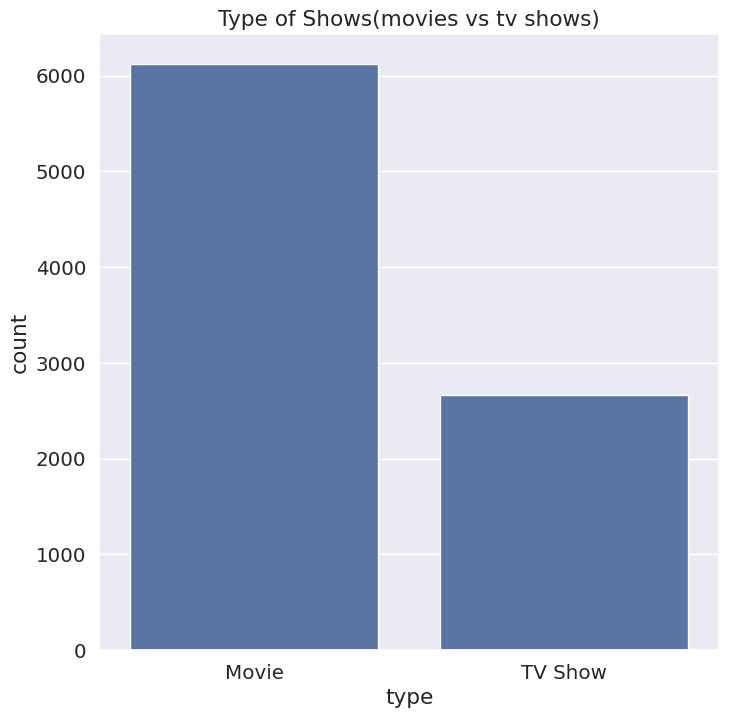

In [17]:
sns.countplot(data=df,x="type")
plt.title("Type of Shows(movies vs tv shows)")
plt.show()

/tmp/ipykernel_2224/1899717082.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10_countries.index,y=top_10_countries.values,palette="coolwarm")


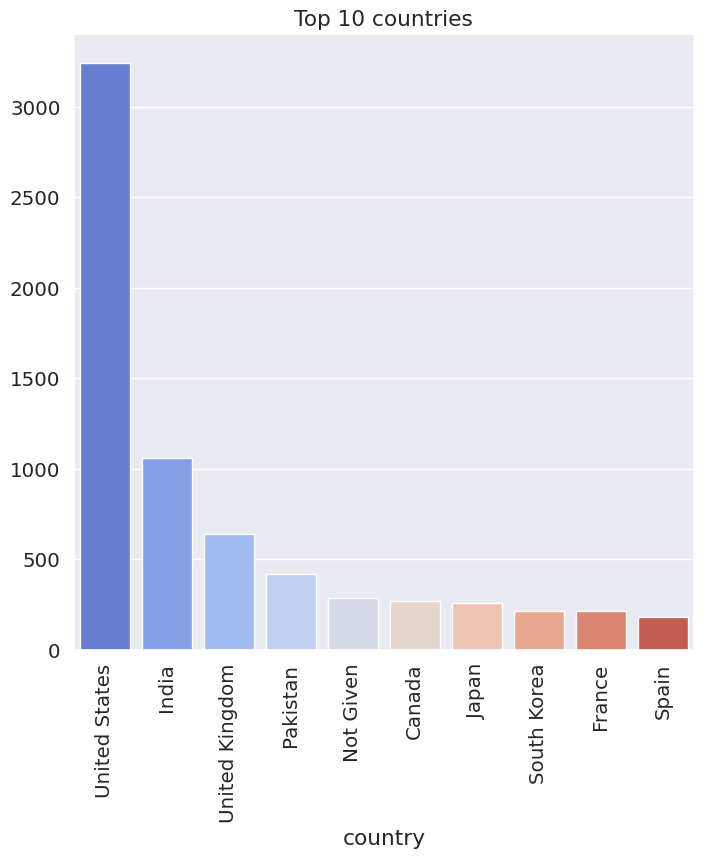

In [18]:
top_10_countries=df["country"].value_counts().head(10)
sns.barplot(x=top_10_countries.index,y=top_10_countries.values,palette="coolwarm")
plt.title("Top 10 countries")
plt.xticks(rotation=90)
plt.show()

/tmp/ipykernel_2224/2276013658.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=ra.index,y=ra.values,palette="coolwarm")


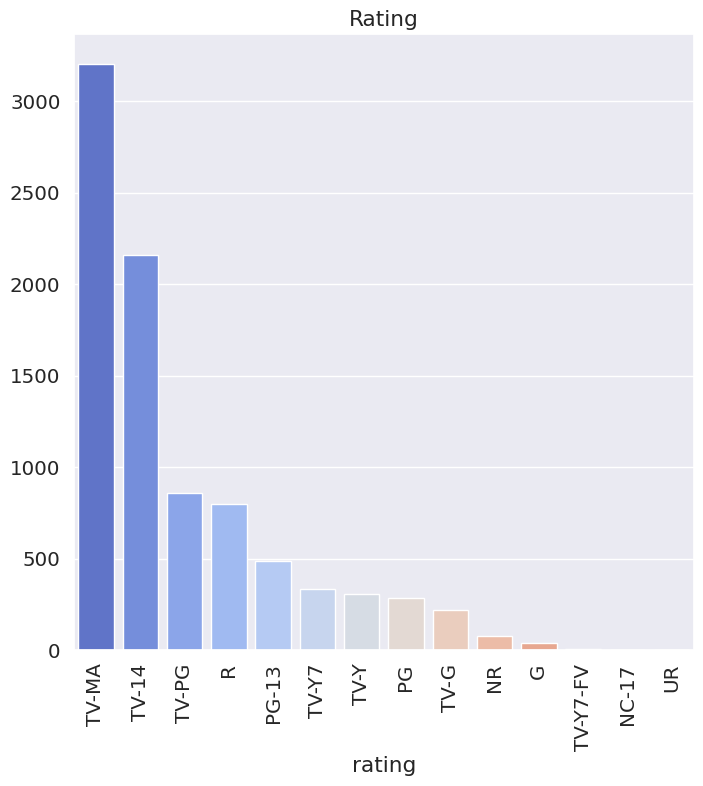

In [19]:
ra=df["rating"].value_counts()
sns.barplot(x=ra.index,y=ra.values,palette="coolwarm")
plt.title("Rating")
plt.xticks(rotation=90)
plt.show()

/tmp/ipykernel_2224/80990977.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=df,x="release_year",palette="coolwarm")


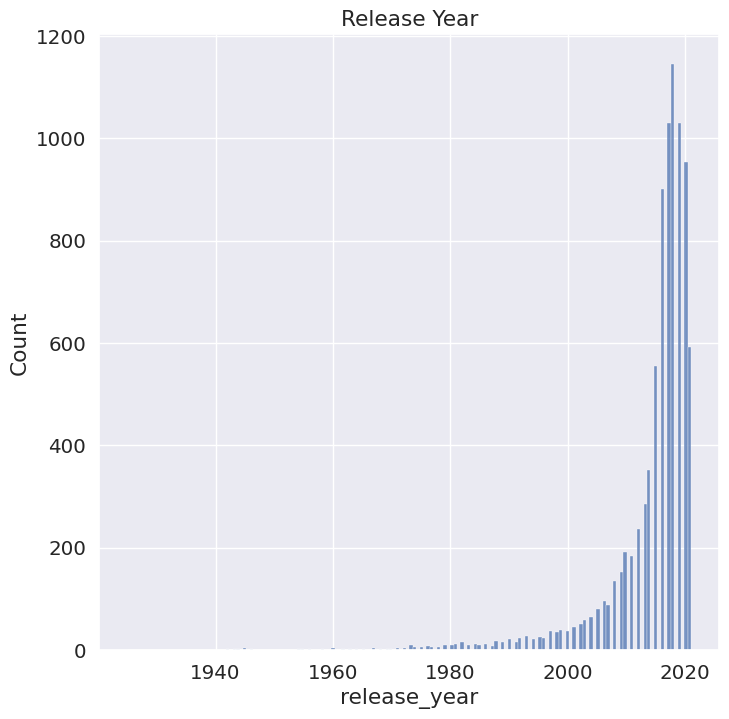

In [20]:
sns.histplot(data=df,x="release_year",palette="coolwarm")
plt.title("Release Year")
plt.show()

/tmp/ipykernel_2224/1393439156.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df,x="year",palette="coolwarm")


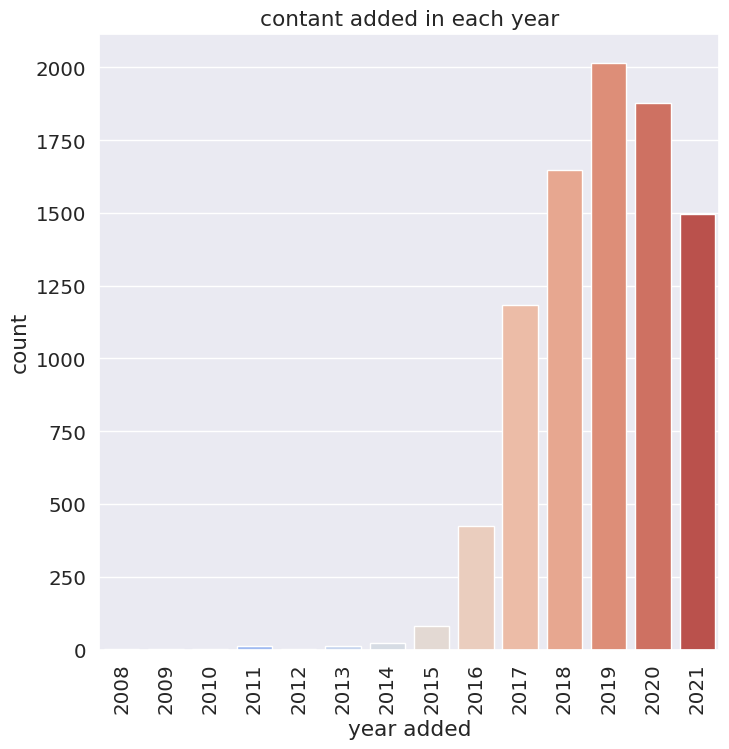

In [21]:
sns.countplot(data=df,x="year",palette="coolwarm")
plt.title("contant added in each year")
plt.xlabel("year added")
plt.xticks(rotation=90)
plt.show()

/tmp/ipykernel_2224/3555305300.py:4: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot(data=tv,x="seasons",palette="coolwarm")


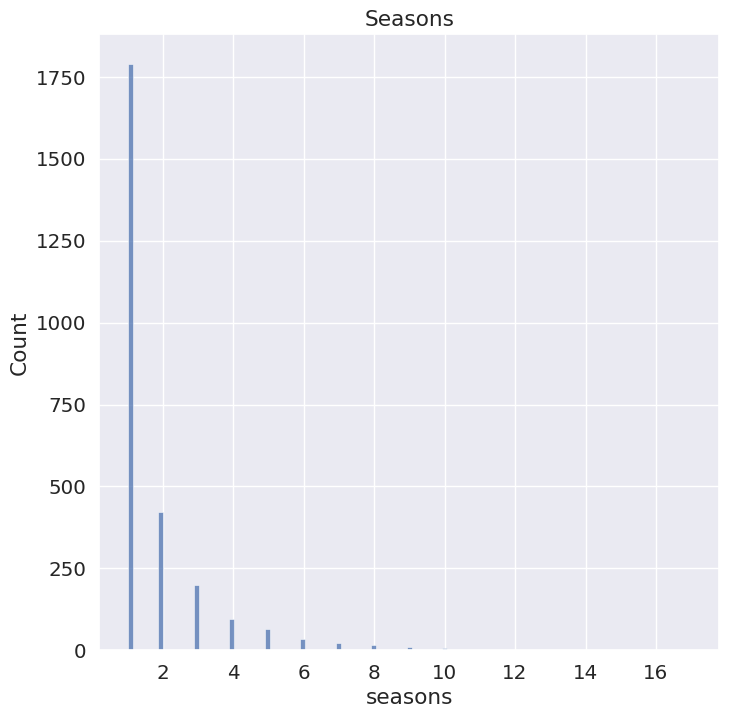

In [23]:
tv=df[df["type"]=="TV Show"].copy()
tv["seasons"]=tv["duration"].str.replace("Seasons","").str.replace("Season","")
tv["seasons"]=tv["seasons"].astype(int)
sns.histplot(data=tv,x="seasons",palette="coolwarm")
plt.title("Seasons")
plt.show()


/tmp/ipykernel_2224/3858995588.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_10_listed_in.index,x=top_10_listed_in.values,palette="coolwarm")


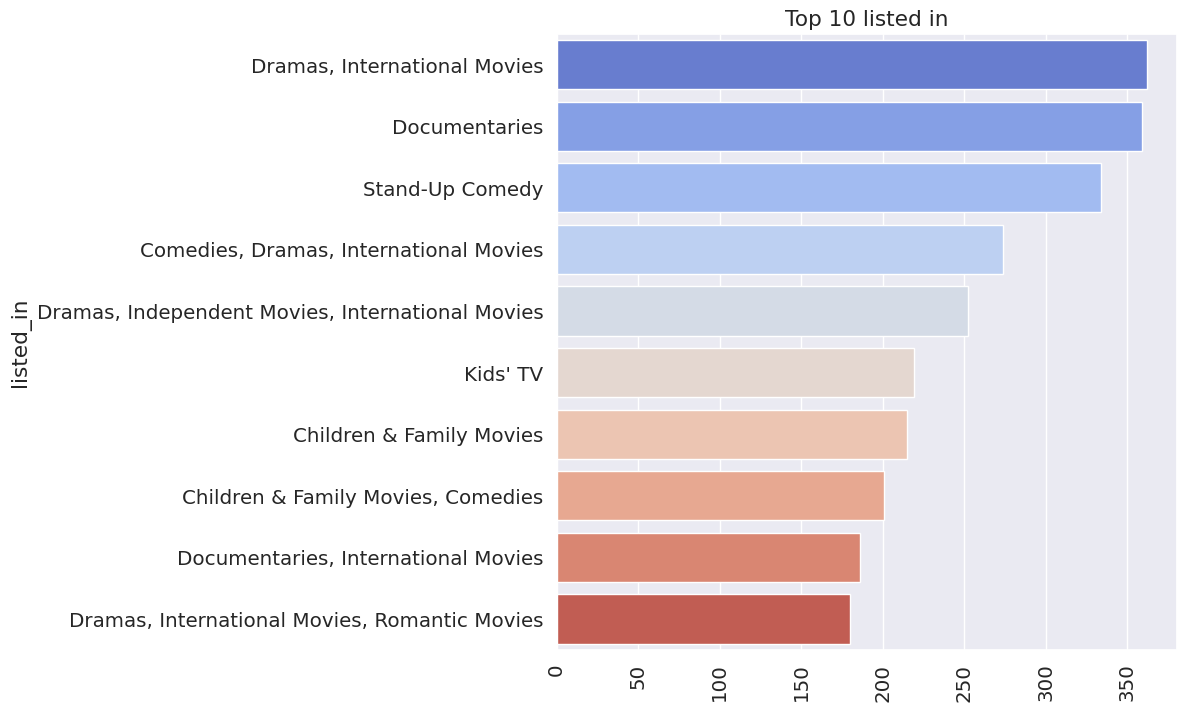

In [24]:
top_10_listed_in=df["listed_in"].value_counts().head(10)
sns.barplot(y=top_10_listed_in.index,x=top_10_listed_in.values,palette="coolwarm")
plt.title("Top 10 listed in")
plt.xticks(rotation=90)
plt.show()

/tmp/ipykernel_2224/1106447213.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=top_10_category.index,x=top_10_category.values,palette="coolwarm")


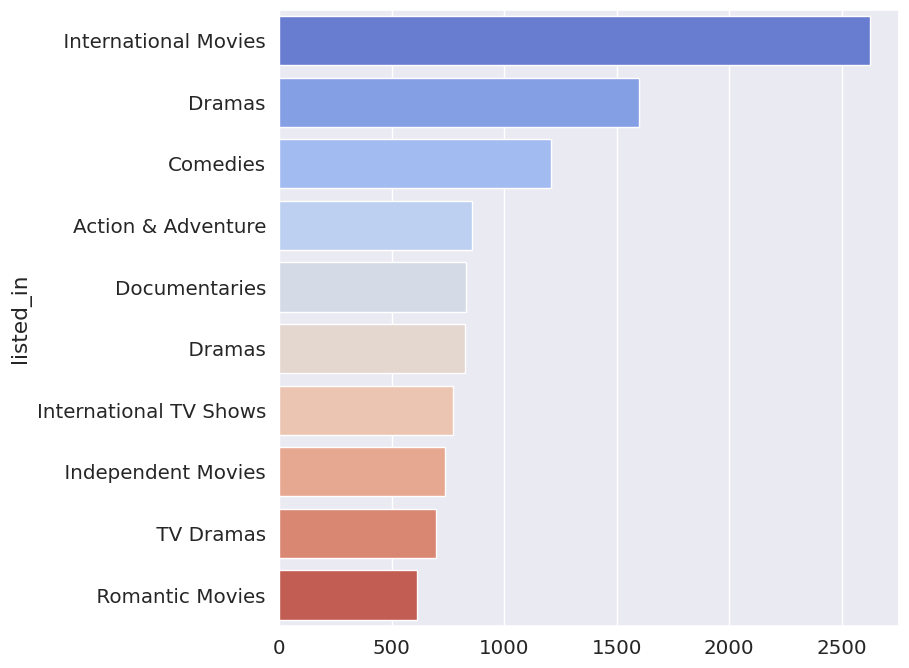

In [26]:
df["listed_in"]=df["listed_in"].str.split(",")
catego=df.explode("listed_in")
top_10_category=catego["listed_in"].value_counts().head(10)
sns.barplot(y=top_10_category.index,x=top_10_category.values,palette="coolwarm")
plt.show()

###Multiple Relation

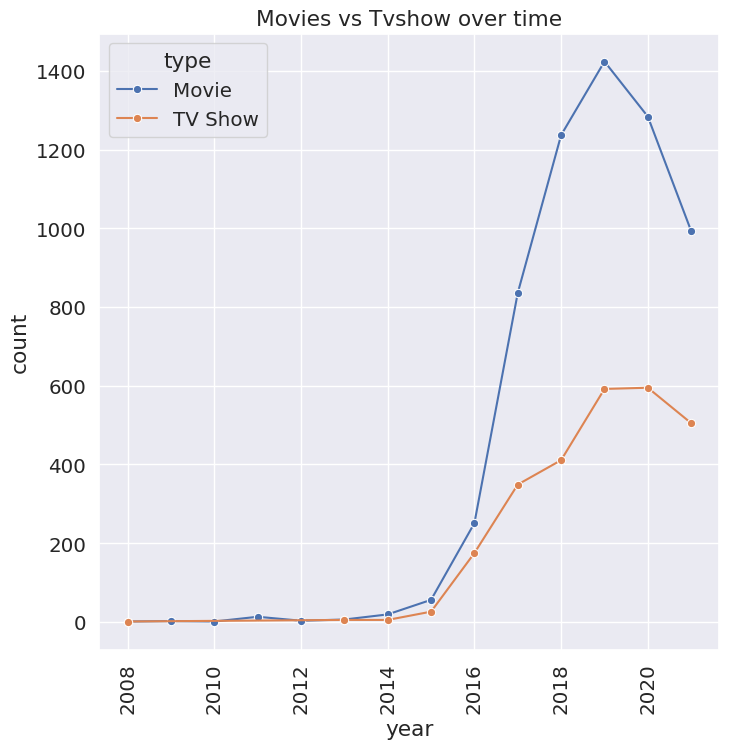

In [27]:
year_type=df.groupby(["year","type"]).size().reset_index(name="count")
sns.lineplot(data=year_type,x="year",y="count",hue="type",marker='o')
plt.title("Movies vs Tvshow over time")
plt.xticks(rotation=90)
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

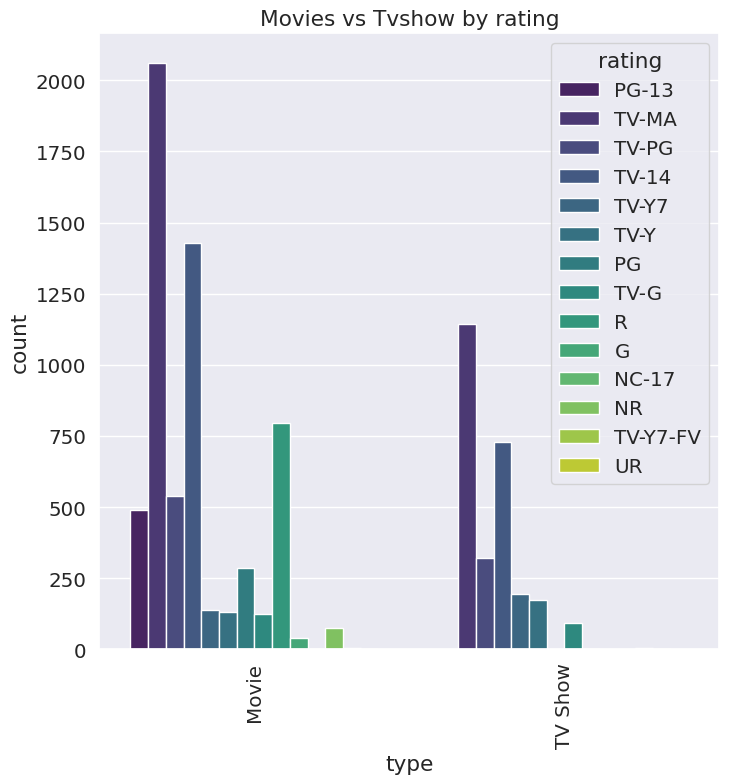

In [28]:
sns.countplot(data=df,x="type",hue="rating",palette="viridis")
plt.title("Movies vs Tvshow by rating")
plt.xticks(rotation=90)
plt.show

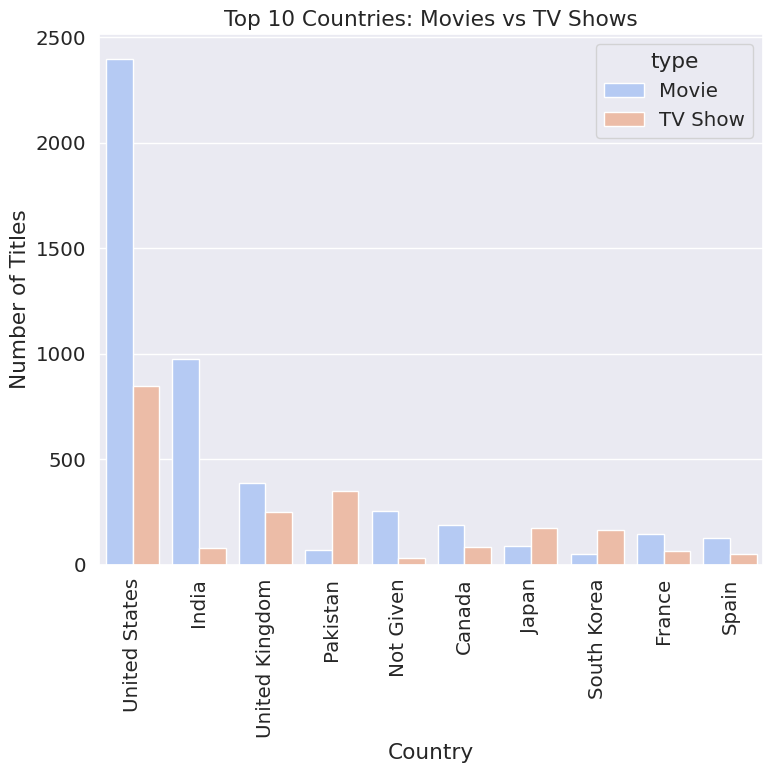

In [29]:
top_10_countries = df["country"].value_counts().head(10).index
df_top10 = df[df["country"].isin(top_10_countries)]
sns.countplot(data=df_top10,x="country",hue="type",order=top_10_countries,palette="coolwarm")

plt.title("Top 10 Countries: Movies vs TV Shows")
plt.xlabel("Country")
plt.ylabel("Number of Titles")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()